# 03b · Caracterización de las demás variables del dataset

**Objetivo (OE1).** El notebook 03 caracteriza el precio de bolsa. Este aplica el mismo análisis a las otras variables
originales del dataset maestro, las que entran al modelo: **demanda real**, **generación total**, **volumen útil de los
embalses**, **aportes hídricos** y el **índice ONI**. Para cada una se describe su nivel, sus ciclos, su contenido en
frecuencia y su relación con el precio.

**Resolución de cada variable.** La demanda y la generación son horarias; los embalses y los aportes, diarios (en el
dataset se repiten en las 24 horas, aquí se usan como diarios), y el ONI, mensual (trimestres móviles de NOAA). El
análisis se adapta a cada resolución: no tiene sentido buscar un ciclo diario en una variable diaria.

**Datos.** Los mismos del notebook 03: dataset oficial (enero de 2019 a 5 de agosto de 2026) más la operación diaria
de `data/produccion/serie_xm.csv`, hasta el último precio publicado. El notebook solo lee datos.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from scipy import signal
from scipy.signal import savgol_filter

warnings.filterwarnings("ignore")
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())

AZUL, NARANJA, AQUA, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#6b6a66", "#1f1f1e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10, "axes.titlesize": 12,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": "#b9b8b2", "axes.labelcolor": TINTA,
                     "xtick.color": GRIS, "ytick.color": GRIS, "legend.frameon": False, "lines.linewidth": 1.4})
azules = LinearSegmentedColormap.from_list("azules", ["#e8f1fc", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
MESES_C = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

# --- datos: dataset oficial + operacion diaria, hasta el ultimo precio publicado (igual que el notebook 03)
oficial = pd.concat([pd.read_csv(RAIZ / "data/processed" / f, parse_dates=["fecha_hora"])
                     for f in ("dataset_maestro_2019_2025.csv", "dataset_maestro_2026.csv")])
operacion = pd.read_csv(RAIZ / "data/produccion/serie_xm.csv", parse_dates=["fecha_hora"])
df = (pd.concat([oficial, operacion[operacion["fecha_hora"] > oficial["fecha_hora"].max()]])
        .drop_duplicates("fecha_hora").set_index("fecha_hora").sort_index())
FIN = df["precio_bolsa"].last_valid_index()
df = df.loc[:FIN]
# dias con la demanda aun parcial: XM publica primero un valor incompleto del ultimo dia y lo completa despues
# (el 1-nov-2026 la demanda era 28 % de la generacion). Se descartan si la demanda queda bajo el 90 % de la generacion.
razon = (df["demanda"] / df["generacion"]).groupby(df.index.normalize()).transform("mean")
DIAS_PARCIALES = sorted(set(df.index[razon < 0.9].normalize().strftime("%d/%m/%Y")))
df.loc[razon < 0.9, "demanda"] = np.nan

# unidades de lectura: MW para demanda y generacion (energia de cada hora), TWh para embalses, GWh/dia para aportes
h = pd.DataFrame({"precio": df["precio_bolsa"], "demanda": df["demanda"] / 1e3, "generacion": df["generacion"] / 1e3},
                 index=df.index)
d = pd.DataFrame({"precio": df["precio_bolsa"].resample("D").mean(),
                  "demanda": h["demanda"].resample("D").mean(), "generacion": h["generacion"].resample("D").mean(),
                  "embalses": df["volumen_embalses"].resample("D").mean() / 1e9,
                  "aportes": df["aportes_hidricos"].resample("D").mean() / 1e6})

# ONI: solo los trimestres ya publicados a la fecha del ultimo precio (ver notebook 03)
TRIM = ["DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ", "JJA", "JAS", "ASO", "SON", "OND", "NDJ"]
oni = (pd.read_csv(RAIZ / "data/produccion/oni_index.csv")
       .melt(id_vars="anio", value_vars=TRIM, var_name="trim", value_name="oni")
       .assign(fecha=lambda t: pd.to_datetime(dict(year=t["anio"], month=t["trim"].map({k: i + 1 for i, k in enumerate(TRIM)}), day=1))))
oni = oni[oni["fecha"] + pd.DateOffset(months=1) < FIN.to_period("M").to_timestamp()].dropna(subset=["oni"])
oni = oni.set_index("fecha")["oni"].sort_index()

def franjas_enso(ax):
    s = oni.loc["2019-01-01":]
    signo = np.sign(s.where(s.abs() >= 0.5, 0))
    for _, g in signo.groupby((signo != signo.shift()).cumsum()):
        if g.iloc[0] != 0:
            ax.axvspan(g.index[0], g.index[-1] + pd.offsets.MonthBegin(1), lw=0,
                       color=NARANJA if g.iloc[0] > 0 else AZUL, alpha=0.12)

def oni_de(fechas):
    return pd.Series([oni.asof(x) if x >= oni.index[0] else np.nan for x in fechas], index=fechas)

print(f"Periodo: {df.index.min():%d/%m/%Y} a {FIN:%d/%m/%Y} | {len(h):,} horas | {len(d):,} días")
print("Días con la demanda aún parcial (descartados):", DIAS_PARCIALES or "ninguno")
print(f"ONI publicado de {oni.index[0]:%m/%Y} a {oni.index[-1]:%m/%Y}")

Periodo: 01/01/2019 a 01/11/2026 | 68,688 horas | 2,862 días
Días con la demanda aún parcial (descartados): ['01/11/2026']
ONI publicado de 01/2018 a 09/2026


## 1. Resumen de las variables
Nivel, dispersión y forma de la distribución de cada variable, en la resolución en que se mide.

In [2]:
def resumen(s, unidad):
    return {"unidad": unidad, "media": s.mean(), "mediana": s.median(), "p05": s.quantile(.05), "p95": s.quantile(.95),
            "mín": s.min(), "máx": s.max(), "CV %": s.std() / s.mean() * 100, "asimetría": s.skew()}

tabla = pd.DataFrame({"Demanda (horaria)": resumen(h["demanda"], "MW"),
                      "Generación (horaria)": resumen(h["generacion"], "MW"),
                      "Embalses (diaria)": resumen(d["embalses"], "TWh"),
                      "Aportes (diaria)": resumen(d["aportes"], "GWh/día"),
                      "ONI (mensual)": resumen(oni.loc["2019-01-01":], "°C")}).T
num = tabla.columns.drop("unidad")
tabla[num] = tabla[num].astype(float).round(2)
tabla.loc["ONI (mensual)", "CV %"] = np.nan      # media cercana a cero: el CV no tiene sentido
tabla

,unidad,media,mediana,p05,p95,mín,máx,CV %,asimetría
Demanda (horaria),MW,8854.99,8892.32,6724.02,10972.35,5022.63,12644.22,14.63,-0.01
Generación (horaria),MW,8922.72,8945.24,6693.76,11123.24,4970.67,12832.28,15.14,-0.02
Embalses (diaria),TWh,11.53,11.70,6.49,14.77,4.97,15.64,21.55,-0.60
Aportes (diaria),GWh/día,188.04,176.30,69.94,346.35,45.17,565.94,45.61,0.88
ONI (mensual),°C,0.09,-0.10,-0.90,1.80,-1.10,2.50,NaN,0.80


In [3]:
anual = pd.DataFrame({"Demanda media (MW)": h["demanda"].groupby(h.index.year).mean(),
                      "Generación media (MW)": h["generacion"].groupby(h.index.year).mean(),
                      "Embalses medios (TWh)": d["embalses"].groupby(d.index.year).mean(),
                      "Embalses mínimos (TWh)": d["embalses"].groupby(d.index.year).min(),
                      "Aportes medios (GWh/día)": d["aportes"].groupby(d.index.year).mean(),
                      "ONI medio": oni.loc["2019-01-01":].groupby(oni.loc["2019-01-01":].index.year).mean()})
anual.index.name = "año"
anual["Crecimiento de la demanda %"] = anual["Demanda media (MW)"].pct_change() * 100
anual.round(1)

,Demanda media (MW),Generación media (MW),Embalses medios (TWh),Embalses mínimos (TWh),Aportes medios (GWh/día),ONI medio,Crecimiento de la demanda %
año,,,,,,,
2019,8097.1,8003.9,10.5,7.3,152.6,0.6,NaN
2020,7921.9,7892.0,9.3,5.4,138.8,-0.2,-2.2
2021,8371.6,8439.9,12.7,9.0,196.6,-0.6,5.7
2022,8655.9,8779.5,13.2,9.6,221.5,-0.8,3.4
2023,9124.9,9210.5,12.7,10.5,190.3,0.8,5.4
2024,9355.8,9478.9,9.0,5.0,168.5,0.4,2.5
2025,9508.7,9636.1,12.5,8.4,248.6,-0.3,1.6
2026,9995.8,10142.7,12.6,10.4,187.5,1.0,5.1


## 2. Las series completas
Promedios diarios con su media móvil de 30 días; las franjas marcan El Niño (naranja) y La Niña (azul).

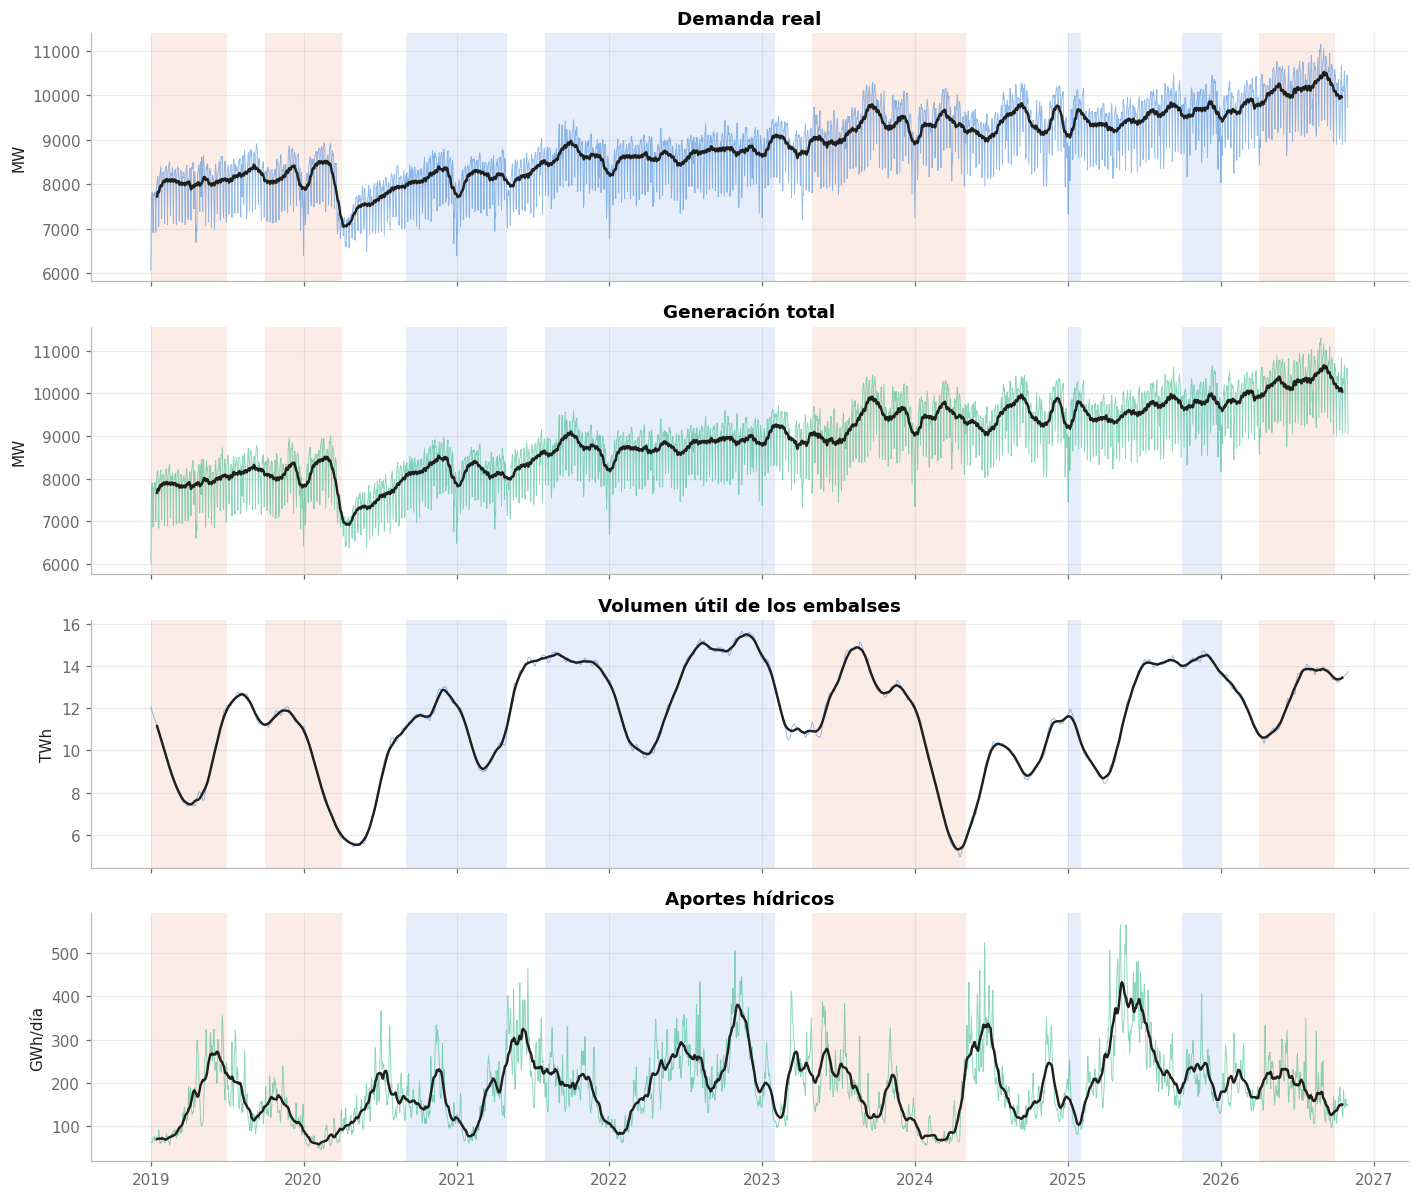

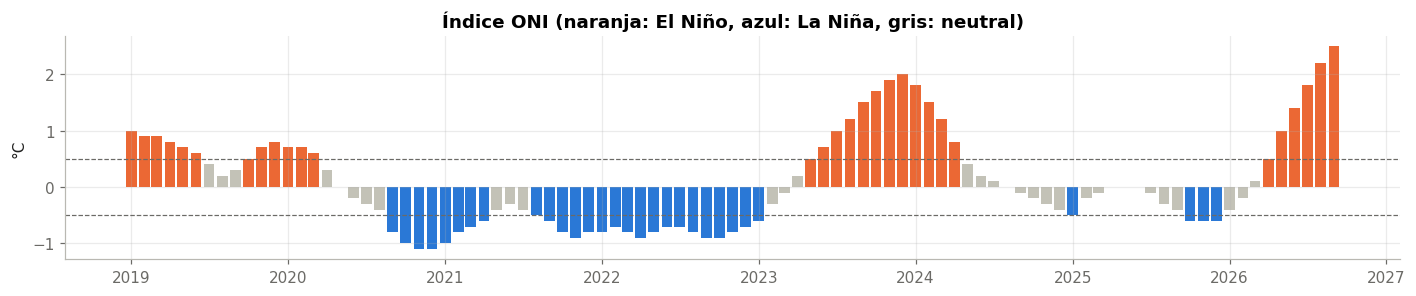

In [4]:
fig, axs = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
for ax, (col, titulo, unidad, color) in zip(axs, [
        ("demanda", "Demanda real", "MW", AZUL), ("generacion", "Generación total", "MW", AQUA),
        ("embalses", "Volumen útil de los embalses", "TWh", AZUL), ("aportes", "Aportes hídricos", "GWh/día", AQUA)]):
    franjas_enso(ax)
    ax.plot(d.index, d[col], color=color, lw=.6, alpha=.5)
    ax.plot(d.index, d[col].rolling(30, center=True).mean(), color=TINTA, lw=1.6)
    ax.set_title(titulo); ax.set_ylabel(unidad)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(13, 2.8))
s = oni.loc["2019-01-01":]
ax.bar(s.index, s, width=25, color=[NARANJA if v >= .5 else AZUL if v <= -.5 else "#c3c2b7" for v in s])
ax.axhline(.5, color=GRIS, ls="--", lw=.8); ax.axhline(-.5, color=GRIS, ls="--", lw=.8)
ax.set_title("Índice ONI (naranja: El Niño, azul: La Niña, gris: neutral)"); ax.set_ylabel("°C")
plt.tight_layout(); plt.show()

## 3. Demanda y generación: ciclos
Las dos son horarias. La generación sigue a la demanda casi uno a uno: la diferencia entre ambas corresponde a las
pérdidas de transmisión, los intercambios internacionales y la medición, así que basta ver los ciclos de la demanda y
comprobar que la generación los repite.

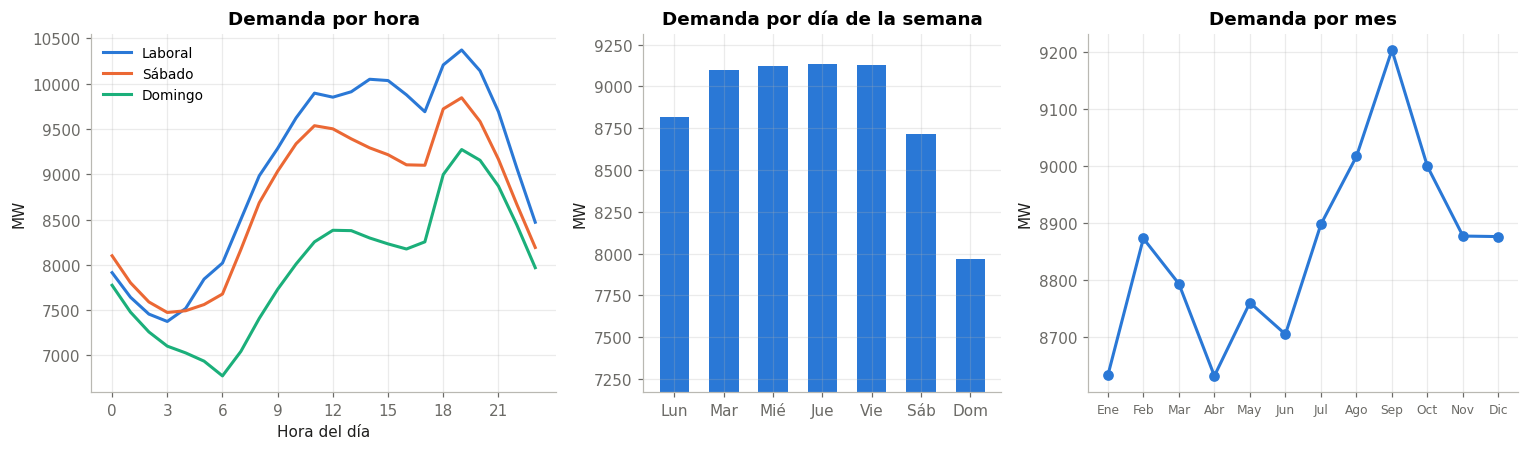

Laboral: máximo a las 19 h (10,372 MW), mínimo a las 03 h (7,376 MW); relación máximo/mínimo 1.41
Domingo: máximo a las 19 h, mínimo a las 06 h; demanda media -12.0% frente a un laboral
Mes de mayor demanda: Sep; de menor: Abr (+6.6% entre ambos)
Generación - demanda: media 68 MW (0.8% de la demanda); correlación horaria entre ambas 0.996


In [5]:
tipo = np.where(h.index.dayofweek < 5, "Laboral", np.where(h.index.dayofweek == 5, "Sábado", "Domingo"))
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.3, 1, 1.2]})
for nombre, color in (("Laboral", AZUL), ("Sábado", NARANJA), ("Domingo", AQUA)):
    sub = h[tipo == nombre]
    axs[0].plot(range(24), sub.groupby(sub.index.hour)["demanda"].mean(), color=color, lw=2, label=nombre)
axs[0].set_title("Demanda por hora"); axs[0].set_xlabel("Hora del día"); axs[0].set_ylabel("MW")
axs[0].set_xticks(range(0, 24, 3)); axs[0].legend(fontsize=9)
dia = h["demanda"].groupby(h.index.dayofweek).mean()
axs[1].bar(range(7), dia, color=AZUL, width=.6)
axs[1].set_xticks(range(7), ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]); axs[1].set_ylim(dia.min() * .9, dia.max() * 1.02)
axs[1].set_title("Demanda por día de la semana"); axs[1].set_ylabel("MW")
mes = h["demanda"].groupby(h.index.month).mean()
axs[2].plot(range(1, 13), mes, "o-", color=AZUL, lw=2)
axs[2].set_xticks(range(1, 13), MESES_C, fontsize=8); axs[2].set_title("Demanda por mes"); axs[2].set_ylabel("MW")
plt.tight_layout(); plt.show()

lab = h[tipo == "Laboral"].groupby(h[tipo == "Laboral"].index.hour)["demanda"].mean()
dom = h[tipo == "Domingo"].groupby(h[tipo == "Domingo"].index.hour)["demanda"].mean()
print(f"Laboral: máximo a las {lab.idxmax():02d} h ({lab.max():,.0f} MW), mínimo a las {lab.idxmin():02d} h ({lab.min():,.0f} MW); "
      f"relación máximo/mínimo {lab.max() / lab.min():.2f}")
print(f"Domingo: máximo a las {dom.idxmax():02d} h, mínimo a las {dom.idxmin():02d} h; demanda media {dom.mean() / lab.mean() - 1:+.1%} frente a un laboral")
print(f"Mes de mayor demanda: {MESES_C[mes.idxmax() - 1]}; de menor: {MESES_C[mes.idxmin() - 1]} ({mes.max() / mes.min() - 1:+.1%} entre ambos)")
dif = h["generacion"] - h["demanda"]
print(f"Generación - demanda: media {dif.mean():,.0f} MW ({dif.mean() / h['demanda'].mean():.1%} de la demanda); "
      f"correlación horaria entre ambas {h['demanda'].corr(h['generacion']):.3f}")

## 4. Demanda y generación: contenido en frecuencia
Mismo método del notebook 03: se resta la tendencia (Savitzky-Golay de 721 h), se estima el espectro con Welch
(ventanas de 16 semanas) y un espectrograma muestra cómo cambia en el tiempo la amplitud del ciclo diario.

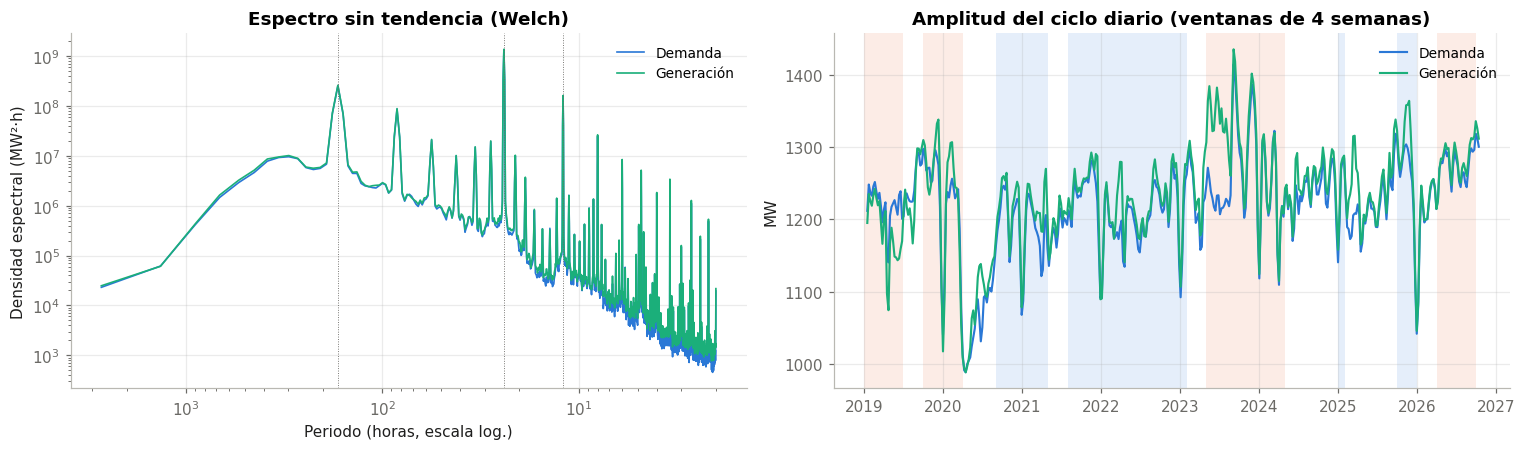

Demanda                            Generación                          
  periodo (h) relativa al ciclo de 24 h periodo (h) relativa al ciclo de 24 h
0        24.0                     1.000        24.0                     1.000
1       168.0                     0.190       168.0                     0.190
2        12.0                     0.119        12.0                     0.118
3        84.0                     0.065        84.0                     0.065
4         8.0                     0.019         8.0                     0.019

In [6]:
def espectro(serie):
    y = serie.interpolate().to_numpy(float)
    r = y - savgol_filter(y, 721, 3)
    f, p = signal.welch(r, fs=1.0, window="hann", nperseg=24 * 7 * 16, noverlap=24 * 7 * 8, detrend="constant")
    return 1 / f[1:], p[1:], r

def amplitud_24h(r, indice):
    nper = 24 * 28
    f_s, t_s, Z = signal.stft(r, fs=1.0, window="hann", nperseg=nper, noverlap=nper - 24 * 7, detrend="constant",
                              boundary=None, padded=False)
    return pd.Series(2 * np.abs(Z[np.argmin(abs(f_s - 1 / 24))]), index=indice[0] + pd.to_timedelta(t_s, unit="h"))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
picos = {}
for col, color, nombre in (("demanda", AZUL, "Demanda"), ("generacion", AQUA, "Generación")):
    periodo, pot, r = espectro(h[col])
    axs[0].loglog(periodo, pot, color=color, lw=1.1, label=nombre)
    pk, _ = signal.find_peaks(np.log(pot), prominence=1.0)
    pk = pk[periodo[pk] <= 200]
    t = pd.DataFrame({"periodo (h)": periodo[pk], "potencia": pot[pk]}).sort_values("potencia", ascending=False).head(5)
    t["relativa al ciclo de 24 h"] = t["potencia"] / pot[np.argmin(abs(periodo - 24))]
    picos[nombre] = t.round({"periodo (h)": 1, "relativa al ciclo de 24 h": 3}).drop(columns="potencia").reset_index(drop=True)
    a = amplitud_24h(r, h.index)
    axs[1].plot(a.index, a, color=color, lw=1.4, label=nombre)
axs[0].invert_xaxis(); axs[0].set_xlabel("Periodo (horas, escala log.)"); axs[0].set_ylabel("Densidad espectral (MW²·h)")
axs[0].set_title("Espectro sin tendencia (Welch)"); axs[0].legend(fontsize=9)
for p_, n_ in ((168, "semana"), (24, "día"), (12, "12 h")):
    axs[0].axvline(p_, color=GRIS, lw=.6, ls=":")
franjas_enso(axs[1])
axs[1].set_title("Amplitud del ciclo diario (ventanas de 4 semanas)"); axs[1].set_ylabel("MW"); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
pd.concat(picos, axis=1)

In [7]:
a_dem = amplitud_24h(espectro(h["demanda"])[2], h.index)
print(f"Amplitud del ciclo diario de la demanda: media {a_dem.mean():,.0f} MW; "
      f"{a_dem.groupby(a_dem.index.year).mean().round(0).to_dict()}")
a_pre = amplitud_24h(espectro(h["precio"])[2], h.index)
print(f"Correlación en el tiempo entre la amplitud diaria de la demanda y la del precio: {a_dem.corr(a_pre):.2f}")

Amplitud del ciclo diario de la demanda: media 1,218 MW; {2019: 1233.0, 2020: 1142.0, 2021: 1203.0, 2022: 1204.0, 2023: 1254.0, 2024: 1234.0, 2025: 1229.0, 2026: 1256.0}
Correlación en el tiempo entre la amplitud diaria de la demanda y la del precio: 0.27


## 5. Embalses y aportes: ciclo anual
Son diarias, así que sus ciclos son de semanas a años. Colombia tiene dos temporadas de lluvia (abril-mayo y
octubre-noviembre) y dos secas (diciembre-marzo y julio-septiembre). En los aportes que llegan a los embalses el
primer pico se corre hacia mayo-julio, por el tiempo que tarda el agua en llegar; los embalses acumulan todo eso con
retraso. La banda muestra los percentiles 10 a 90 de cada día del año entre 2019 y 2025, y la
línea, lo ocurrido en 2026.

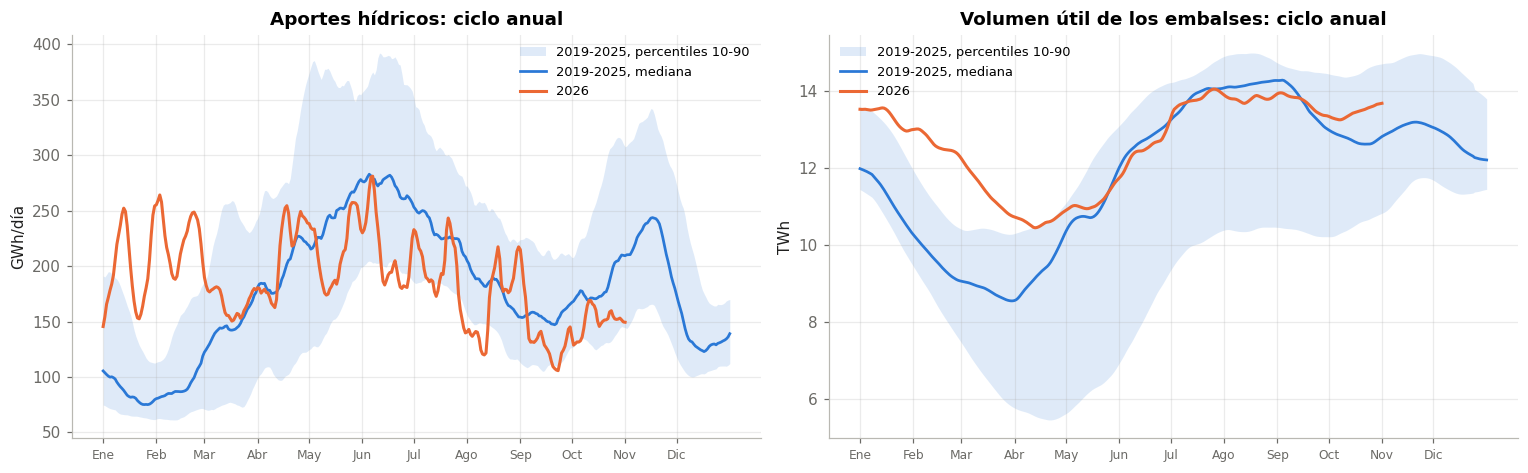

Aportes medios por mes (GWh/día): {'Ene': 103, 'Feb': 101, 'Mar': 152, 'Abr': 200, 'May': 258, 'Jun': 282, 'Jul': 242, 'Ago': 185, 'Sep': 161, 'Oct': 195, 'Nov': 232, 'Dic': 144}
Embalses: máximo medio en Nov (13.2 TWh), mínimo en Abr (8.4 TWh)
Último dato: embalses 13.7 TWh el 01/11/2026 (mediana 2019-2025 para ese día del año: 12.7 TWh)


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, col, unidad, titulo in ((axs[0], "aportes", "GWh/día", "Aportes hídricos"), (axs[1], "embalses", "TWh", "Volumen útil de los embalses")):
    base = d.loc[:"2025-12-31", col]
    clima = base.groupby(base.index.dayofyear)
    lo, me, hi = clima.quantile(.1), clima.median(), clima.quantile(.9)
    ax.fill_between(lo.index, lo.rolling(15, center=True, min_periods=1).mean(), hi.rolling(15, center=True, min_periods=1).mean(),
                    color=AZUL, alpha=.15, lw=0, label="2019-2025, percentiles 10-90")
    ax.plot(me.index, me.rolling(15, center=True, min_periods=1).mean(), color=AZUL, lw=1.8, label="2019-2025, mediana")
    s26 = d.loc["2026-01-01":, col]
    ax.plot(s26.index.dayofyear, s26.rolling(7, center=True, min_periods=1).mean(), color=NARANJA, lw=2, label="2026")
    ax.set_xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335], MESES_C, fontsize=8)
    ax.set_title(titulo + ": ciclo anual"); ax.set_ylabel(unidad); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

mes_ap = d["aportes"].loc[:"2025-12-31"].groupby(d.loc[:"2025-12-31"].index.month).mean()
mes_em = d["embalses"].loc[:"2025-12-31"].groupby(d.loc[:"2025-12-31"].index.month).mean()
print("Aportes medios por mes (GWh/día):", {MESES_C[m - 1]: round(v) for m, v in mes_ap.items()})
print(f"Embalses: máximo medio en {MESES_C[mes_em.idxmax() - 1]} ({mes_em.max():.1f} TWh), mínimo en {MESES_C[mes_em.idxmin() - 1]} ({mes_em.min():.1f} TWh)")
ult = d["embalses"].last_valid_index()
print(f"Último dato: embalses {d.loc[ult, 'embalses']:.1f} TWh el {ult:%d/%m/%Y} (mediana 2019-2025 para ese día del año: "
      f"{d['embalses'].loc[:'2025-12-31'].groupby(d.loc[:'2025-12-31'].index.dayofyear).median()[ult.dayofyear]:.1f} TWh)")

### 5.1 Contenido en frecuencia de la hidrología
Espectro de las series diarias (Welch, ventanas de 2 años). Con casi ocho años de datos se resuelven el ciclo anual
(365 días) y el semestral (182 días, las dos temporadas de lluvia).

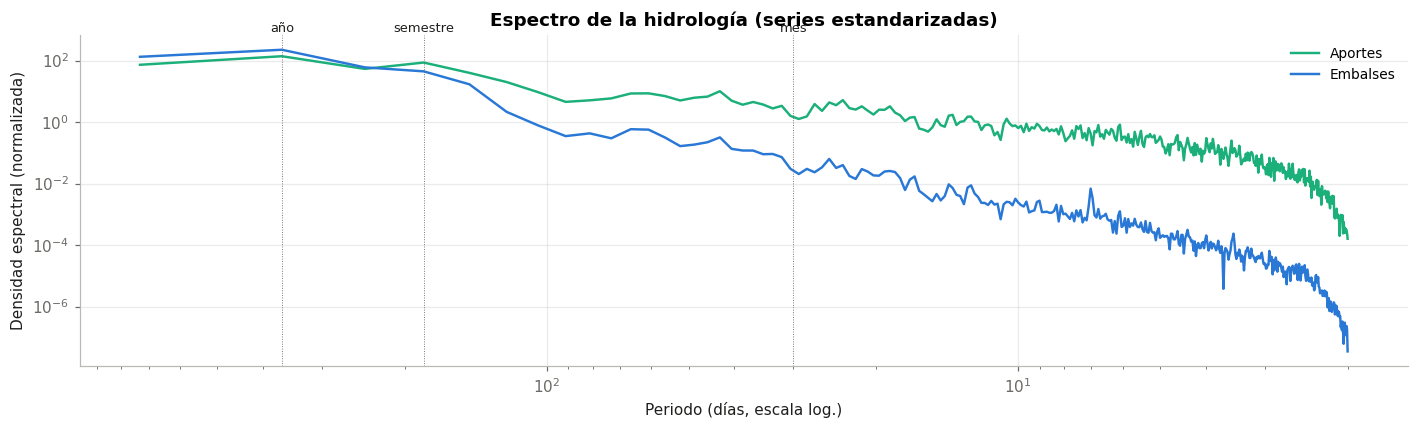

,potencia a 365 días / anual,potencia a 182 días / anual,potencia a 30 días / anual
Aportes,1.0,0.623,0.011
Embalses,1.0,0.198,0.000


In [9]:
fig, ax = plt.subplots(figsize=(13, 4))
tabla_h = {}
for col, color, nombre in (("aportes", AQUA, "Aportes"), ("embalses", AZUL, "Embalses")):
    y = d[col].interpolate().to_numpy(float)
    y = (y - y.mean()) / y.std()
    f, p = signal.welch(y, fs=1.0, window="hann", nperseg=730, noverlap=365, detrend="linear")
    periodo = 1 / f[1:]
    ax.loglog(periodo, p[1:], color=color, lw=1.6, label=nombre)
    tabla_h[nombre] = {f"{x} días": p[1:][np.argmin(abs(periodo - x))] / p[1:][np.argmin(abs(periodo - 365))] for x in (365, 182, 30)}
ax.invert_xaxis()
for x, n in ((365, "año"), (182, "semestre"), (30, "mes")):
    ax.axvline(x, color=GRIS, lw=.6, ls=":"); ax.text(x, ax.get_ylim()[1], n, ha="center", va="bottom", fontsize=8.5, color=TINTA)
ax.set_xlabel("Periodo (días, escala log.)"); ax.set_ylabel("Densidad espectral (normalizada)")
ax.set_title("Espectro de la hidrología (series estandarizadas)"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
pd.DataFrame(tabla_h).T.round(3).rename(columns=lambda c: f"potencia a {c} / anual")

### 5.2 Los embalses integran los aportes
Desde el punto de vista de señales, el embalse se comporta como un integrador con fugas: acumula lo que entra (aportes)
menos lo que se turbina. Por eso su cambio diario se relaciona con los aportes del mismo día, y su nivel, con los
aportes acumulados de semanas. Aquí se mide con qué ventana de aportes acumulados se explica mejor el nivel.

In [10]:
cambio = d["embalses"].diff()
print(f"Correlación del cambio diario del embalse con los aportes del mismo día: {cambio.corr(d['aportes']):.2f}")
ventanas = [7, 15, 30, 60, 90, 120, 180, 240, 300, 365]
c = pd.Series({w: d["embalses"].corr(d["aportes"].rolling(w).sum()) for w in ventanas}, name="correlación")
c.index.name = "aportes acumulados (días)"
print(f"El nivel del embalse se explica mejor con los aportes acumulados de {c.idxmax()} días (correlación {c.max():.2f})")
c.to_frame().T.round(3)

Correlación del cambio diario del embalse con los aportes del mismo día: 0.75
El nivel del embalse se explica mejor con los aportes acumulados de 180 días (correlación 0.78)


aportes acumulados (días),7,15,30,60,90,120,180,240,300,365
correlación,0.371,0.431,0.52,0.657,0.739,0.774,0.78,0.751,0.642,0.546


## 6. El ONI se adelanta a la hidrología
El Niño reduce las lluvias en Colombia, pero con retraso. Correlación entre el ONI y los aportes y los embalses del mes,
con el ONI adelantado de 0 a 12 meses (un rezago de *k* meses compara el ONI de hace *k* meses con la hidrología de hoy).

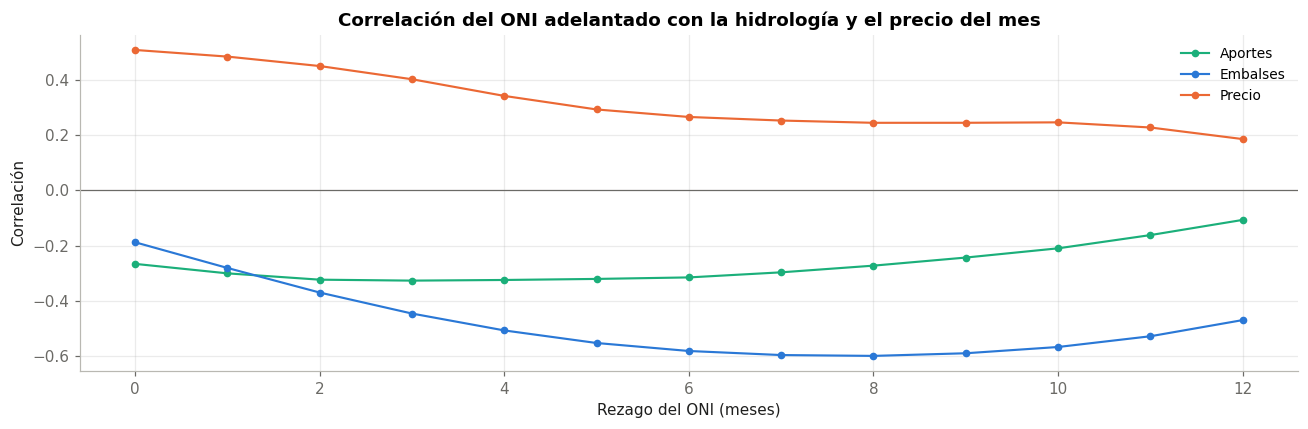

{'aportes': 'más fuerte con 3 meses (-0.33)', 'embalses': 'más fuerte con 8 meses (-0.60)', 'precio': 'más fuerte con 0 meses (+0.51)'}


,aportes,embalses,precio
rezago del ONI (meses),,,
0,-0.266,-0.188,0.509
2,-0.324,-0.370,0.451
4,-0.325,-0.507,0.342
6,-0.315,-0.582,0.266
9,-0.243,-0.590,0.245
12,-0.107,-0.470,0.186


In [11]:
mens = d[["aportes", "embalses", "precio"]].resample("MS").mean()
rez = range(0, 13)
t = pd.DataFrame({v: [mens[v].corr(oni.shift(k).reindex(mens.index)) for k in rez] for v in ("aportes", "embalses", "precio")},
                 index=pd.Index(rez, name="rezago del ONI (meses)"))
fig, ax = plt.subplots(figsize=(12, 4))
for v, color, n in (("aportes", AQUA, "Aportes"), ("embalses", AZUL, "Embalses"), ("precio", NARANJA, "Precio")):
    ax.plot(t.index, t[v], "o-", ms=4, color=color, label=n)
ax.axhline(0, color=GRIS, lw=.8); ax.set_xlabel("Rezago del ONI (meses)"); ax.set_ylabel("Correlación")
ax.set_title("Correlación del ONI adelantado con la hidrología y el precio del mes"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
print({v: f"más fuerte con {t[v].abs().idxmax()} meses ({t[v].loc[t[v].abs().idxmax()]:+.2f})" for v in t.columns})
t.loc[[0, 2, 4, 6, 9, 12]].round(3)

## 7. Relación de cada variable con el precio
Correlación de cada variable con el precio, en promedios diarios, con la variable rezagada de 0 a 30 días. Es la
pregunta que importa para el pronóstico: cuánto dice cada variable del precio que vendrá.

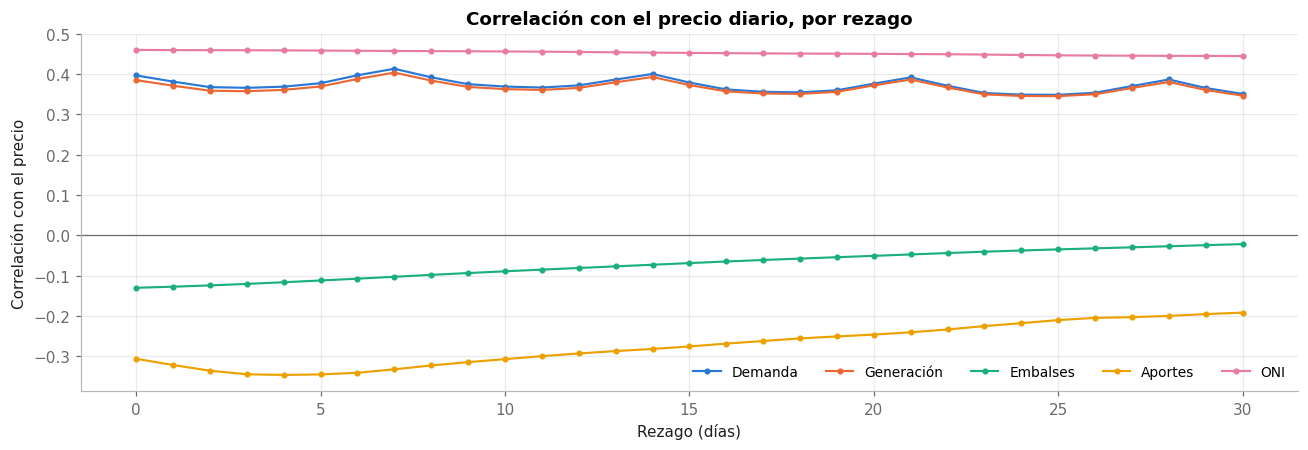

,demanda,generacion,embalses,aportes,oni
rezago (días),,,,,
0,0.397,0.385,-0.130,-0.306,0.460
1,0.381,0.371,-0.127,-0.321,0.459
3,0.366,0.357,-0.120,-0.344,0.459
7,0.413,0.404,-0.102,-0.332,0.457
14,0.400,0.393,-0.073,-0.281,0.453
30,0.351,0.347,-0.022,-0.191,0.445


In [12]:
rez = range(0, 31)
dd = d.copy(); dd["oni"] = oni_de(dd.index)
corr = pd.DataFrame({v: [dd["precio"].corr(dd[v].shift(k)) for k in rez] for v in ("demanda", "generacion", "embalses", "aportes", "oni")},
                    index=pd.Index(rez, name="rezago (días)"))
fig, ax = plt.subplots(figsize=(12, 4.2))
# cinco series: los cinco primeros colores de la paleta validada, en su orden fijo
for v, color, n in (("demanda", AZUL, "Demanda"), ("generacion", NARANJA, "Generación"), ("embalses", AQUA, "Embalses"),
                    ("aportes", "#eda100", "Aportes"), ("oni", "#e87ba4", "ONI")):
    ax.plot(corr.index, corr[v], "o-", ms=3, color=color, label=n)
ax.axhline(0, color=GRIS, lw=.8); ax.set_xlabel("Rezago (días)"); ax.set_ylabel("Correlación con el precio")
ax.set_title("Correlación con el precio diario, por rezago"); ax.legend(fontsize=9, ncol=5)
plt.tight_layout(); plt.show()
corr.loc[[0, 1, 3, 7, 14, 30]].round(3)

### 7.1 Dos matices de esas correlaciones
La correlación lineal resume la relación en un número y puede engañar. Dos comprobaciones: (1) la demanda y el precio
crecieron los dos con los años; se repite la correlación sin esa tendencia común (restando a cada serie su media móvil
de un año). (2) La relación entre embalses y precio puede no ser lineal; se compara el precio en cada quintil del
volumen de los embalses.

In [13]:
sin_tend = lambda s: s - s.rolling(365, center=True, min_periods=180).mean()
print(f"Precio-demanda (diaria): {d['precio'].corr(d['demanda']):.2f} con la tendencia; "
      f"{sin_tend(d['precio']).corr(sin_tend(d['demanda'])):.2f} sin la tendencia de largo plazo")
q = pd.qcut(d["embalses"], 5, labels=["1 (más bajos)", "2", "3", "4", "5 (más altos)"])
quint = d.groupby(q, observed=True).agg(**{"embalses medios (TWh)": ("embalses", "mean"), "precio medio": ("precio", "mean"),
                                            "precio mediano": ("precio", "median")})
quint.index.name = "quintil del volumen de los embalses"
print(f"Correlación de rango (Spearman) embalses-precio: {d['precio'].corr(d['embalses'], method='spearman'):.2f}")
quint.round(1)

Precio-demanda (diaria): 0.40 con la tendencia; 0.17 sin la tendencia de largo plazo
Correlación de rango (Spearman) embalses-precio: -0.22


,embalses medios (TWh),precio medio,precio mediano
quintil del volumen de los embalses,,,
1 (más bajos),7.7,416.7,302.0
2,10.4,346.3,255.3
3,11.7,305.7,234.5
4,13.3,447.9,356.5
5 (más altos),14.5,226.6,163.3


## 8. Conclusiones
Cifras de la ejecución con datos hasta el 1 de noviembre de 2026. El 1 de noviembre la demanda todavía era un valor
parcial de XM (28 % de la generación) y se descartó.

1. **Demanda: crece y repite su forma.** Pasó de 8.097 MW de promedio en 2019 a 9.971 MW en 2026 (+23 %); solo bajó en
   2020, por la pandemia (−2,2 %). Su ciclo diario es estable: mínimo a las 3 h (7.376 MW en días laborales), máximo a
   las 19 h (10.372 MW, 1,41 veces el mínimo), y el domingo baja 12 %. El ciclo anual es débil (6,6 % entre septiembre,
   el mes más alto, y abril, el más bajo). En el espectro dominan el ciclo de 24 h, el semanal de 168 h (19 % de la
   potencia del diario) y el armónico de 12 h (12 %).
2. **La amplitud diaria de la demanda no cambia con El Niño; la del precio sí.** La diferencia día-noche de la demanda
   se mantiene en unos 1.200 MW todos los años, mientras que la del precio se dispara en épocas de escasez (notebook 03).
   La correlación en el tiempo entre ambas amplitudes es solo 0,27: lo que amplía el ciclo diario del precio es la
   oferta (el agua disponible), no la demanda.
3. **Generación ≈ demanda.** Correlación horaria de 0,996 y diferencia media de 68 MW (0,8 %, pérdidas e intercambios).
   Como variable del modelo, la generación casi no agrega información a la demanda.
4. **Aportes: dos temporadas de lluvia.** Mínimo en enero-febrero (unos 100 GWh/día) y máximos en junio (282) y
   noviembre (232); el ciclo semestral tiene 62 % de la potencia del anual. Es la variable más variable del dataset
   (coeficiente de variación de 46 %).
5. **Embalses: un integrador de los aportes.** Su cambio diario se correlaciona 0,75 con los aportes del mismo día, y su
   nivel se explica mejor con los aportes acumulados de unos 180 días (0,78). Vaciado de diciembre a abril (mínimo medio
   8,4 TWh) y llenado hasta noviembre (13,2 TWh). Los dos peores mínimos (5,4 TWh en 2020 y 5,0 en 2024) llegaron después
   de un El Niño. En 2026 el año empezó con los embalses altos (13,5 TWh, frente a una mediana de 12), lo que amortiguó
   El Niño 2026.
6. **El ONI anticipa la hidrología.** Los aportes responden con unos 3 meses de rezago (correlación −0,33) y los embalses,
   que acumulan, con unos 8 meses (−0,60). Es la cadena ONI → lluvia → aportes → embalses → precio, y por eso el ONI
   sirve como variable aunque llegue con dos meses de retraso.
7. **Qué dice cada variable del precio.** En promedios diarios, la que más se relaciona con el precio es el ONI (0,46,
   casi igual con cualquier rezago, porque cambia despacio), seguida de la demanda (0,40) y los aportes (−0,31; −0,35 con
   3 a 5 días de rezago). Dos matices: buena parte de la relación con la demanda es la tendencia que comparten (sin ella
   baja a 0,17), y la de los embalses no es lineal: con los embalses en su quintil más bajo el precio promedia 417
   COP/kWh y en el más alto 227, pero el cuarto quintil también es caro (448). Esos días caros con embalses altos son de
   El Niño 2023 y El Niño 2026: con los embalses llenos, el agua se ofertó cara anticipando la sequía. Por eso el modelo
   combina hidrología y ONI en vez de usar una sola variable.